## Machine Learning Regression Task: Electric Vehicle Price Prediction

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [3]:
df=pd.read_csv('cars_data_RAW.csv')
print(df.head())

   Row_ID  title                          model  battery  price-range  \
0       1  Tesla                        Model 3     57.5          104   
1       2  Tesla                        Model Y     57.5          137   
2       3  Tesla  Model Y Long Range Dual Motor     75.0          130   
3       4  Tesla  Model 3 Long Range Dual Motor     75.0          106   
4       5  Tesla         Model Y Long Range RWD     75.0          109   

   0 - 100 Top Speed  Range* Efficiency* Fastcharge*  \
0  6.1 sec  201 km/h  415 km   139 Wh/km    690 km/h   
1  6.9 sec  217 km/h  350 km   164 Wh/km    580 km/h   
2  5.0 sec  217 km/h  435 km   172 Wh/km    670 km/h   
3  4.4 sec  201 km/h  500 km   150 Wh/km    770 km/h   
4  5.9 sec  217 km/h  460 km   163 Wh/km    710 km/h   

  Germany_price_before_incentives Netherlands_price_before_incentives  \
0                         €41,970                             €41,990   
1                         €45,970                             €45,990   
2    

In [5]:
df = df.drop(
    columns = [
        "Germany_price_before_incentives",
        "Netherlands_price_before_incentives",
        "UK_price_after_incentives",
        "Drive_Configuration",
        "Tow_Hitch",
        "Towing_capacity_in_kg",
        "Number_of_seats"])
        

In [6]:
df.head()

,Row_ID,title,model,battery,price-range,0 - 100,Top Speed,Range*,Efficiency*,Fastcharge*
0,1,Tesla,Model 3,57.5,104,6.1 sec,201 km/h,415 km,139 Wh/km,690 km/h
1,2,Tesla,Model Y,57.5,137,6.9 sec,217 km/h,350 km,164 Wh/km,580 km/h
2,3,Tesla,Model Y Long Range Dual Motor,75.0,130,5.0 sec,217 km/h,435 km,172 Wh/km,670 km/h
3,4,Tesla,Model 3 Long Range Dual Motor,75.0,106,4.4 sec,201 km/h,500 km,150 Wh/km,770 km/h
4,5,Tesla,Model Y Long Range RWD,75.0,109,5.9 sec,217 km/h,460 km,163 Wh/km,710 km/h


In [7]:
df.tail()

,Row_ID,title,model,battery,price-range,0 - 100,Top Speed,Range*,Efficiency*,Fastcharge*
348,349,Mercedes-benz,eVito Tourer Long 60 kWh,60.0,311,12.0 sec,160 km/h,220 km,273 Wh/km,210 km/h
349,350,Mercedes-benz,eVito Tourer Extra-Long 60 kWh,60.0,322,12.0 sec,160 km/h,215 km,279 Wh/km,200 km/h
350,351,Kgm,Torres EVX,72.0,130,8.1 sec,175 km/h,350 km,206 Wh/km,390 km/h
351,352,Mini,Aceman E,38.5,163,7.9 sec,160 km/h,230 km,167 Wh/km,370 km/h
352,353,Mini,Aceman SE,49.8,137,7.1 sec,170 km/h,300 km,166 Wh/km,430 km/h


In [9]:
df.shape


(353, 10)

In [10]:
print(df.columns)

Index(['Row_ID', 'title', 'model', 'battery', 'price-range', '0 - 100',
       'Top Speed', 'Range*', 'Efficiency*', 'Fastcharge*'],
      dtype='str')


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 353 entries, 0 to 352
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Row_ID       353 non-null    int64  
 1   title        353 non-null    str    
 2   model        353 non-null    str    
 3   battery      353 non-null    float64
 4   price-range  353 non-null    int64  
 5   0 - 100      353 non-null    str    
 6   Top Speed    353 non-null    str    
 7   Range*       353 non-null    str    
 8   Efficiency*  353 non-null    str    
 9   Fastcharge*  353 non-null    str    
dtypes: float64(1), int64(2), str(7)
memory usage: 48.4 KB


In [12]:
df.describe()

,Row_ID,battery,price-range
count,353.000000,353.000000,353.000000
mean,177.000000,74.250142,174.427762
std,102.046558,20.854211,78.834738
min,1.000000,21.300000,90.000000
25%,89.000000,60.000000,127.000000
50%,177.000000,77.000000,150.000000
75%,265.000000,90.000000,197.000000
max,353.000000,123.000000,828.000000


## Task 2 — Data Cleaning

In [13]:
df.rename(columns={'price-range':'price'}, inplace=True)

In [14]:
df.columns

Index(['Row_ID', 'title', 'model', 'battery', 'price', '0 - 100', 'Top Speed',
       'Range*', 'Efficiency*', 'Fastcharge*'],
      dtype='str')

In [15]:
df.isnull().sum()

Row_ID         0
title          0
model          0
battery        0
price          0
0 - 100        0
Top Speed      0
Range*         0
Efficiency*    0
Fastcharge*    0
dtype: int64

In [16]:
(df.isnull().sum() / len(df)) * 100

Row_ID         0.0
title          0.0
model          0.0
battery        0.0
price          0.0
0 - 100        0.0
Top Speed      0.0
Range*         0.0
Efficiency*    0.0
Fastcharge*    0.0
dtype: float64

In [17]:
print("Number of Duplicate rows:", df.duplicated().sum())

Number of Duplicate rows: 0


In [18]:
df = df.drop_duplicates()

In [19]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [20]:
numeric_columns = [
    'battery',
    'price',
    '0 - 100',
    'Top Speed',
    'Range*',
    'Efficiency*',
    'Fastcharge*'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.extract(r'([-+]?\d*\.?\d+)')[0],
        errors='coerce'
    )

In [21]:
df.rename(columns={
    '0 - 100':'acceleration',
    'Top Speed':'top_speed',
    'Range*':'range_km',
    'Efficiency*':'efficiency',
    'Fastcharge*':'fastcharge'
}, inplace=True)

In [22]:
df.head()

,Row_ID,title,model,battery,price,acceleration,top_speed,range_km,efficiency,fastcharge
0,1,Tesla,Model 3,57.5,104,6.1,201,415,139,690.0
1,2,Tesla,Model Y,57.5,137,6.9,217,350,164,580.0
2,3,Tesla,Model Y Long Range Dual Motor,75.0,130,5.0,217,435,172,670.0
3,4,Tesla,Model 3 Long Range Dual Motor,75.0,106,4.4,201,500,150,770.0
4,5,Tesla,Model Y Long Range RWD,75.0,109,5.9,217,460,163,710.0


In [23]:
df.isnull().sum()

Row_ID          0
title           0
model           0
battery         0
price           0
acceleration    0
top_speed       0
range_km        0
efficiency      0
fastcharge      3
dtype: int64

In [24]:
numeric_columns = [
    'battery',
    'price',
    'acceleration',
    'top_speed',
    'range_km',
    'efficiency',
    'fastcharge'
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [25]:
df.isnull().sum()

Row_ID          0
title           0
model           0
battery         0
price           0
acceleration    0
top_speed       0
range_km        0
efficiency      0
fastcharge      0
dtype: int64

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 353 entries, 0 to 352
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Row_ID        353 non-null    int64  
 1   title         353 non-null    str    
 2   model         353 non-null    str    
 3   battery       353 non-null    float64
 4   price         353 non-null    int64  
 5   acceleration  353 non-null    float64
 6   top_speed     353 non-null    int64  
 7   range_km      353 non-null    int64  
 8   efficiency    353 non-null    int64  
 9   fastcharge    353 non-null    float64
dtypes: float64(3), int64(5), str(2)
memory usage: 35.2 KB


In [27]:
df[numeric_columns].describe()

,battery,price,acceleration,top_speed,range_km,efficiency,fastcharge
count,353.000000,353.000000,353.000000,353.00000,353.000000,353.000000,353.000000
mean,74.250142,174.427762,6.592918,187.72238,393.371105,188.056657,598.498584
std,20.854211,78.834738,2.509602,34.29115,96.582783,24.537823,236.053636
min,21.300000,90.000000,2.200000,125.00000,135.000000,139.000000,170.000000
25%,60.000000,127.000000,4.700000,160.00000,335.000000,170.000000,440.000000
50%,77.000000,150.000000,6.500000,180.00000,400.000000,184.000000,570.000000
75%,90.000000,197.000000,8.000000,205.00000,465.000000,202.000000,700.000000
max,123.000000,828.000000,19.100000,325.00000,665.000000,286.000000,1290.000000


## Task 3 — Exploratory Data Analysis

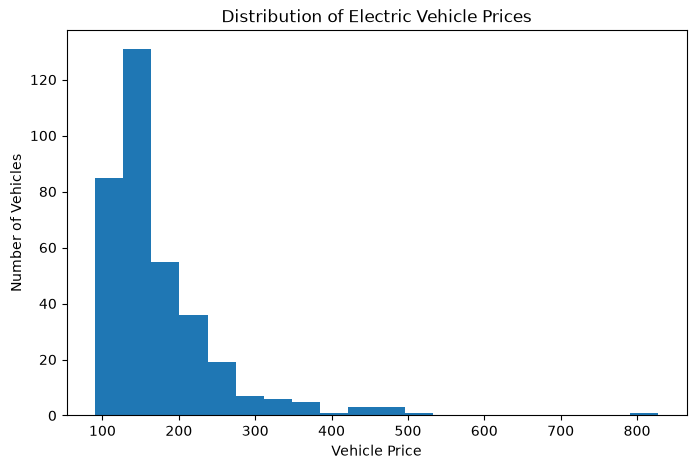

In [28]:
plt.figure(figsize=(8,5))

plt.hist(df['price'], bins=20)

plt.xlabel("Vehicle Price")
plt.ylabel("Number of Vehicles")
plt.title("Distribution of Electric Vehicle Prices")

plt.show()

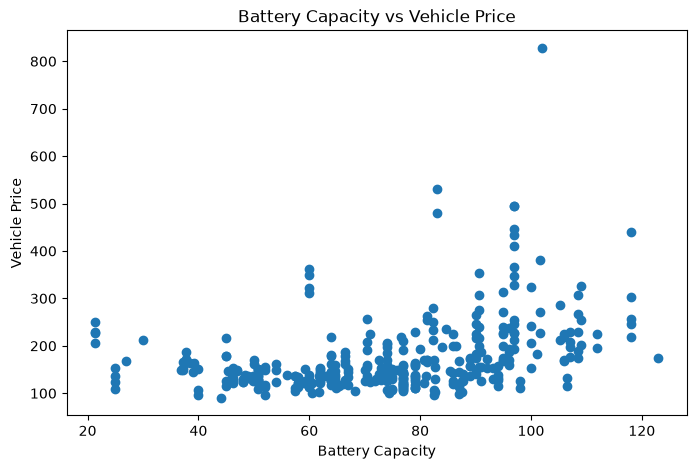

In [29]:
plt.figure(figsize=(8,5))

plt.scatter(df['battery'], df['price'])

plt.xlabel("Battery Capacity")
plt.ylabel("Vehicle Price")
plt.title("Battery Capacity vs Vehicle Price")

plt.show()

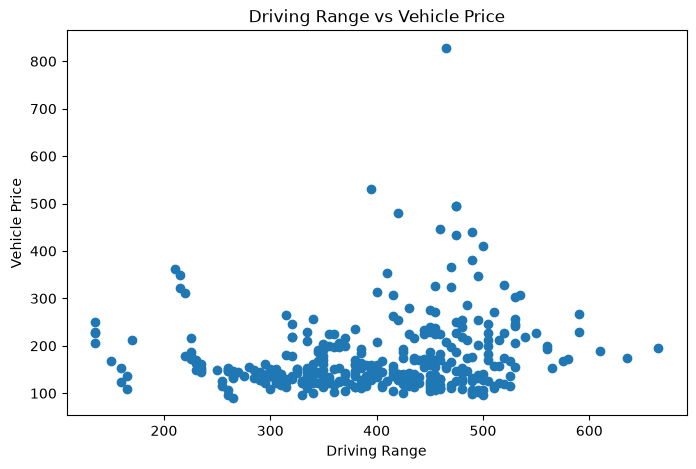

In [30]:
plt.figure(figsize=(8,5))

plt.scatter(df['range_km'], df['price'])

plt.xlabel("Driving Range")
plt.ylabel("Vehicle Price")
plt.title("Driving Range vs Vehicle Price")

plt.show()

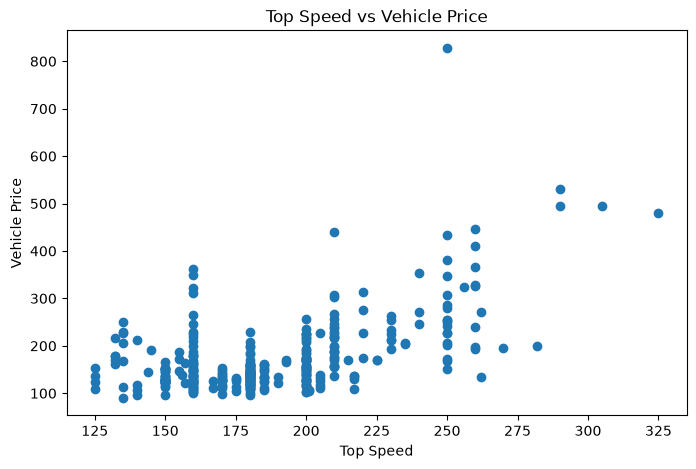

In [31]:
plt.figure(figsize=(8,5))

plt.scatter(df['top_speed'], df['price'])

plt.xlabel("Top Speed")
plt.ylabel("Vehicle Price")
plt.title("Top Speed vs Vehicle Price")

plt.show()

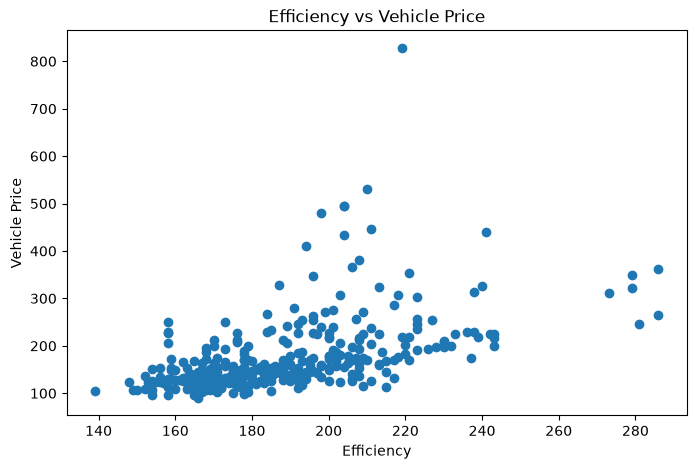

In [32]:
plt.figure(figsize=(8,5))

plt.scatter(df['efficiency'], df['price'])

plt.xlabel("Efficiency")
plt.ylabel("Vehicle Price")
plt.title("Efficiency vs Vehicle Price")

plt.show()

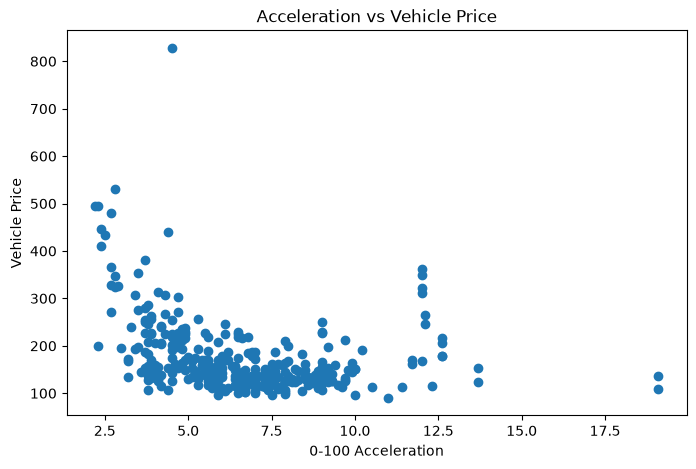

In [33]:
plt.figure(figsize=(8,5))

plt.scatter(df['acceleration'], df['price'])

plt.xlabel("0-100 Acceleration")
plt.ylabel("Vehicle Price")
plt.title("Acceleration vs Vehicle Price")

plt.show()

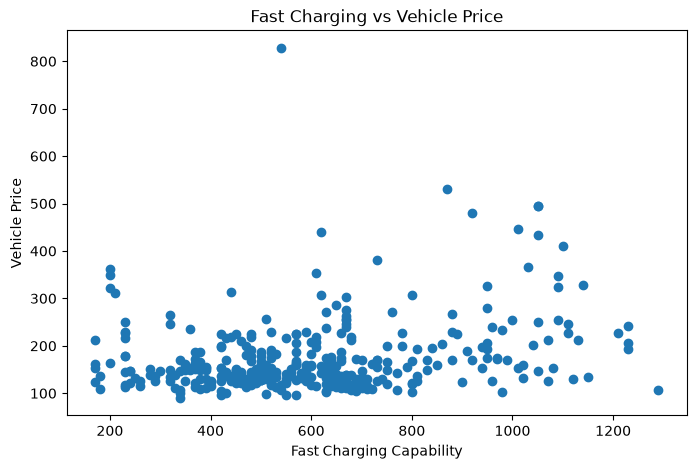

In [34]:
plt.figure(figsize=(8,5))

plt.scatter(df['fastcharge'], df['price'])

plt.xlabel("Fast Charging Capability")
plt.ylabel("Vehicle Price")
plt.title("Fast Charging vs Vehicle Price")

plt.show()

In [35]:
corr_columns = [
    'battery',
    'price',
    'acceleration',
    'top_speed',
    'range_km',
    'efficiency',
    'fastcharge'
]

corr_matrix = df[corr_columns].corr()

corr_matrix

,battery,price,acceleration,top_speed,range_km,efficiency,fastcharge
battery,1.000000,0.377914,-0.663924,0.708803,0.900162,0.518859,0.607004
price,0.377914,1.000000,-0.342327,0.568126,0.162868,0.526576,0.267569
acceleration,-0.663924,-0.342327,1.000000,-0.789492,-0.682326,-0.165124,-0.614654
top_speed,0.708803,0.568126,-0.789492,1.000000,0.690564,0.261759,0.724064
range_km,0.900162,0.162868,-0.682326,0.690564,1.000000,0.115992,0.708845
efficiency,0.518859,0.526576,-0.165124,0.261759,0.115992,1.000000,0.003188
fastcharge,0.607004,0.267569,-0.614654,0.724064,0.708845,0.003188,1.000000


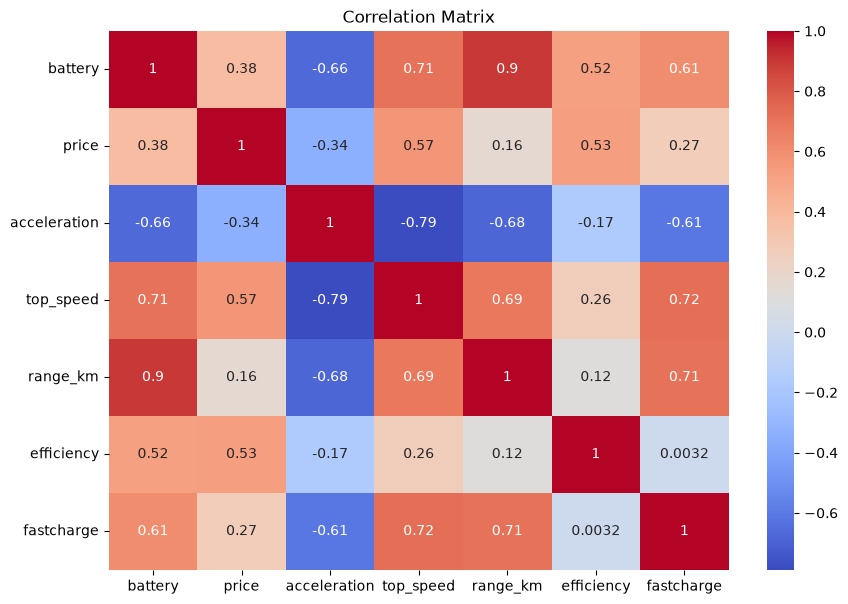

In [36]:
plt.figure(figsize=(10,7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")

plt.show()

## Task 5 — Data Preprocessing

In [37]:
X = df[
    [
        'title',
        'battery',
        'acceleration',
        'top_speed',
        'range_km',
        'efficiency',
        'fastcharge'
    ]
]

y = df['price']

In [41]:
X = pd.get_dummies( X, columns=['title'], drop_first=True )

In [42]:
X = X.astype(int)

In [43]:
X.head()

,battery,acceleration,top_speed,range_km,efficiency,fastcharge,title_Aiways,title_Alfa romeo,title_Audi,title_Bmw,...,title_Ssangyong,title_Subaru,title_Tesla,title_Toyota,title_Vinfast,title_Volkswagen,title_Volvo,title_Voyah,title_Xpeng,title_Zeekr
0,57,6,201,415,139,690,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,57,6,217,350,164,580,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,75,5,217,435,172,670,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,75,4,201,500,150,770,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,75,5,217,460,163,710,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


## Task 6 — Train-Test Split

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (282, 60)
Testing data: (71, 60)


## Task 7 — Linear Regression

In [47]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [48]:
linear_model = LinearRegression()

In [49]:
linear_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](60,)","[72.46,-7.52,38.31,...,-3.7 ,-9.02,-5.31]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,173.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,60
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(55)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](60,)","[36.33,22.05,18.98,..., 0. , 0. , 0. ]"


In [50]:
linear_pred = linear_model.predict(X_test_scaled)

In [51]:
linear_mae = mean_absolute_error(y_test, linear_pred)

linear_mse = mean_squared_error(y_test, linear_pred)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

Linear Regression
MAE: 27.020697568740307
MSE: 4765.731247027903
RMSE: 69.03427588544623
R2 Score: 0.5462650021995891


## Task 8 — Decision Tree Regression

In [52]:
dt_model = DecisionTreeRegressor(
    random_state=42
)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [53]:
dt_pred = dt_model.predict(X_test)

In [54]:
dt_mae = mean_absolute_error(y_test, dt_pred)

dt_mse = mean_squared_error(y_test, dt_pred)

dt_rmse = np.sqrt(dt_mse)

dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Regression")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Regression
MAE: 31.007042253521128
MSE: 6050.052816901409
RMSE: 77.78208544968057
R2 Score: 0.42398751434397497


In [55]:
dt_train_pred = dt_model.predict(X_train)

dt_train_r2 = r2_score(y_train, dt_train_pred)

dt_test_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Training R2:", dt_train_r2)
print("Decision Tree Testing R2:", dt_test_r2)

Decision Tree Training R2: 0.9980648999938911
Decision Tree Testing R2: 0.42398751434397497


## Task 9 — Random Forest Regression

In [56]:
rf_model = RandomForestRegressor(
    random_state=42
)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [57]:
rf_pred = rf_model.predict(X_test)

In [58]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Regression")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Regression
MAE: 26.061609993293093
MSE: 5855.485268544915
RMSE: 76.5211426244075
R2 Score: 0.4425118711634286


## Task 10 — Compare the Three Models

In [59]:
comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree Regressor',
        'Random Forest Regressor'
    ],

    'MAE': [
        linear_mae,
        dt_mae,
        rf_mae
    ],

    'MSE': [
        linear_mse,
        dt_mse,
        rf_mse
    ],

    'RMSE': [
        linear_rmse,
        dt_rmse,
        rf_rmse
    ],

    'R2 Score': [
        linear_r2,
        dt_r2,
        rf_r2
    ]
})

comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,27.020698,4765.731247,69.034276,0.546265
1,Decision Tree Regressor,31.007042,6050.052817,77.782085,0.423988
2,Random Forest Regressor,26.061610,5855.485269,76.521143,0.442512


## Task 11 — Actual vs Predicted

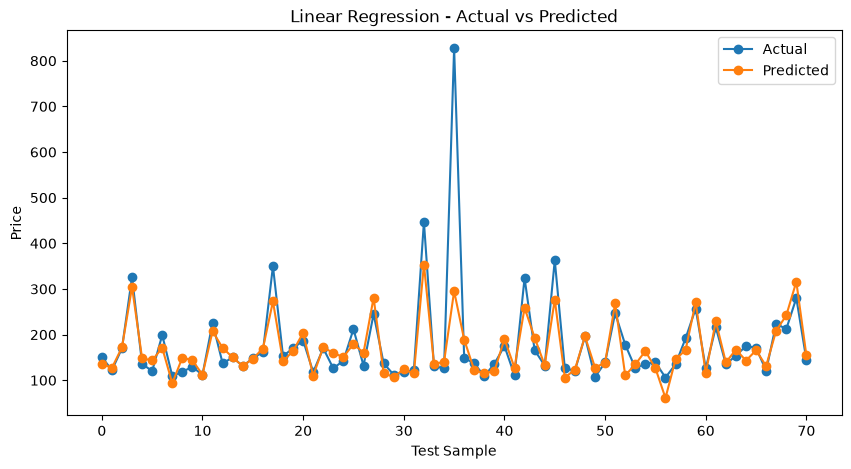

In [60]:
plt.figure(figsize=(10,5))

plt.plot(
    range(len(y_test.values)),
    y_test.values,
    marker='o',
    label="Actual"
)

plt.plot(
    range(len(linear_pred)),
    linear_pred,
    marker='o',
    label="Predicted"
)

plt.xlabel("Test Sample")
plt.ylabel("Price")
plt.title("Linear Regression - Actual vs Predicted")

plt.legend()
plt.show()

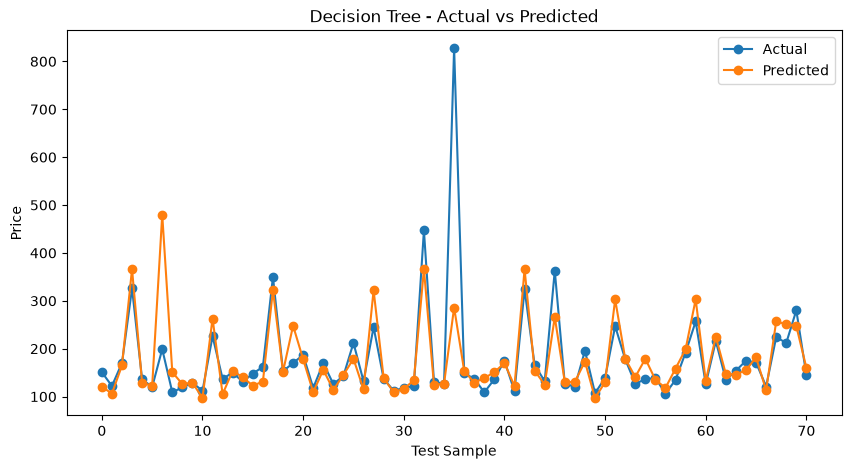

In [61]:
plt.figure(figsize=(10,5))

plt.plot(
    range(len(y_test.values)),
    y_test.values,
    marker='o',
    label="Actual"
)

plt.plot(
    range(len(dt_pred)),
    dt_pred,
    marker='o',
    label="Predicted"
)

plt.xlabel("Test Sample")
plt.ylabel("Price")
plt.title("Decision Tree - Actual vs Predicted")

plt.legend()
plt.show()

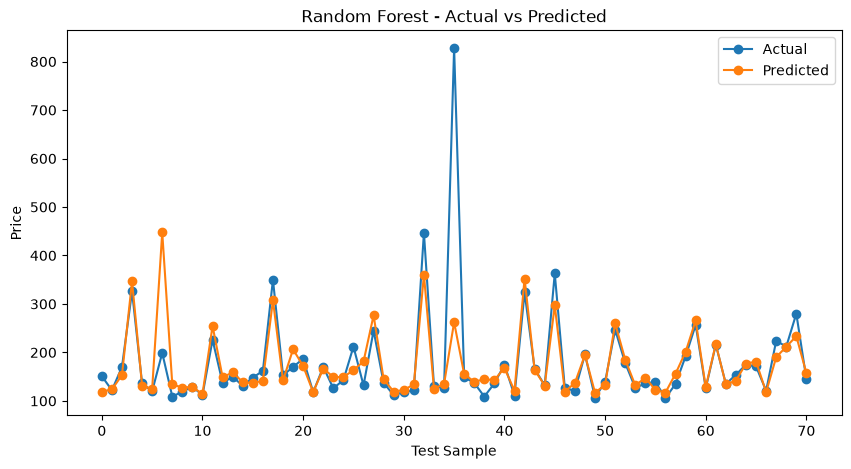

In [62]:
plt.figure(figsize=(10,5))

plt.plot(
    range(len(y_test.values)),
    y_test.values,
    marker='o',
    label="Actual"
)

plt.plot(
    range(len(rf_pred)),
    rf_pred,
    marker='o',
    label="Predicted"
)

plt.xlabel("Test Sample")
plt.ylabel("Price")
plt.title("Random Forest - Actual vs Predicted")

plt.legend()
plt.show()

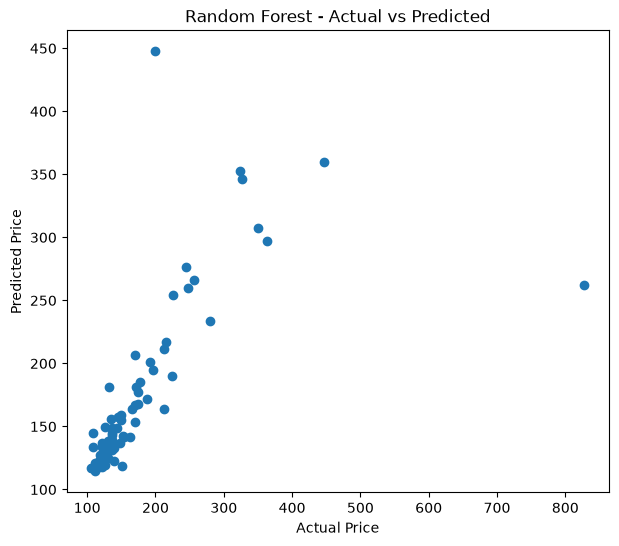

In [63]:
plt.figure(figsize=(7,6))

plt.scatter(y_test, rf_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Random Forest - Actual vs Predicted")

plt.show()

In [64]:
error_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': rf_pred
})

error_df['Error'] = (
    error_df['Actual'] - error_df['Predicted']
).abs()

error_df = error_df.sort_values(
    by='Error',
    ascending=False
)

error_df.head(10)

,Actual,Predicted,Error
35,828,262.340000,565.660000
6,199,447.450000,248.450000
32,447,360.040000,86.960000
45,363,297.290000,65.710000
26,132,181.320000,49.320000
25,212,163.666667,48.333333
69,280,233.530000,46.470000
17,350,307.500000,42.500000
19,170,206.465833,36.465833
38,109,144.477571,35.477571


## Task 12 — Feature Importance

In [65]:
importance_dt = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
})

importance_dt = importance_dt.sort_values(
    by='Importance',
    ascending=False
)

importance_dt.head(15)

,Feature,Importance
1,acceleration,0.438124
4,efficiency,0.249147
2,top_speed,0.118588
36,title_Mercedes-benz,0.062589
5,fastcharge,0.038152
3,range_km,0.036299
39,title_Nio,0.011008
0,battery,0.010725
9,title_Bmw,0.010040
44,title_Porsche,0.008344


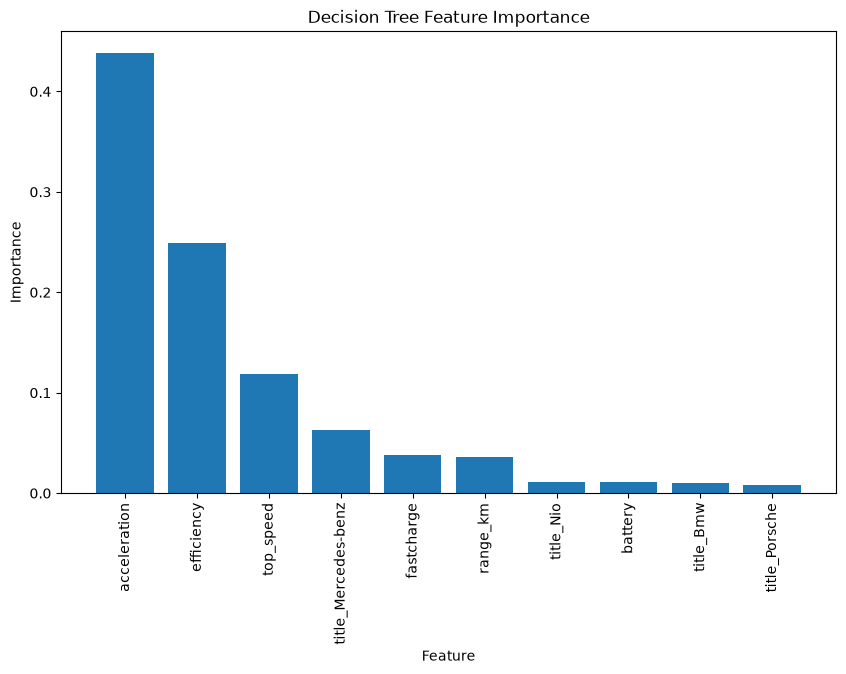

In [66]:
plt.figure(figsize=(10,6))

plt.bar(
    importance_dt['Feature'].head(10),
    importance_dt['Importance'].head(10)
)

plt.xticks(rotation=90)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Decision Tree Feature Importance")

plt.show()

In [67]:
importance_rf = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance_rf = importance_rf.sort_values(
    by='Importance',
    ascending=False
)

importance_rf.head(15)

,Feature,Importance
1,acceleration,0.362917
2,top_speed,0.247994
4,efficiency,0.213612
0,battery,0.042584
3,range_km,0.038669
5,fastcharge,0.026984
36,title_Mercedes-benz,0.025076
9,title_Bmw,0.014673
39,title_Nio,0.005993
44,title_Porsche,0.005547


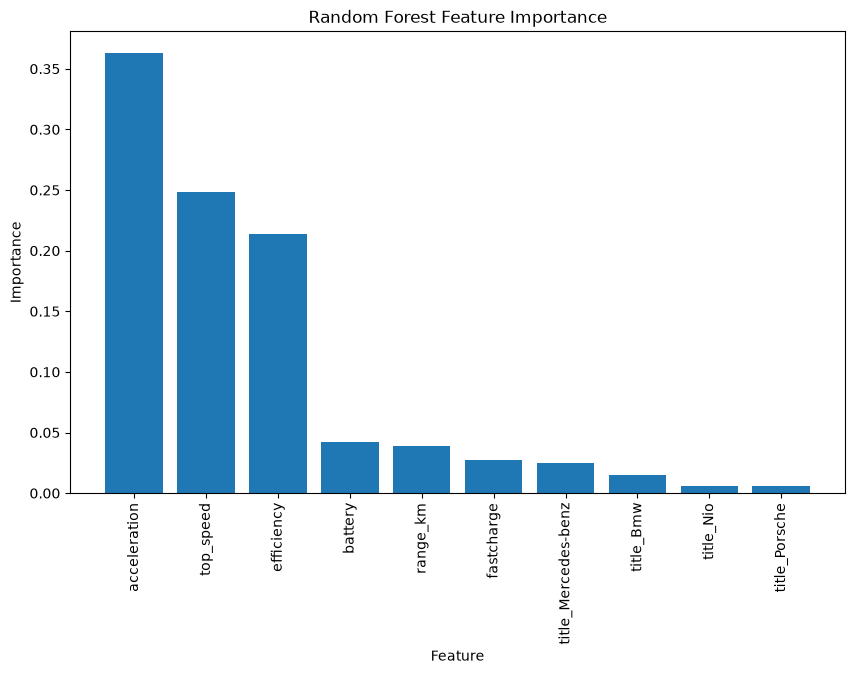

In [68]:
plt.figure(figsize=(10,6))

plt.bar(
    importance_rf['Feature'].head(10),
    importance_rf['Importance'].head(10)
)

plt.xticks(rotation=90)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")

plt.show()

In [69]:
print("Decision Tree Top Features")
print(importance_dt.head(10))

print("\nRandom Forest Top Features")
print(importance_rf.head(10))

Decision Tree Top Features
                Feature  Importance
1          acceleration    0.438124
4            efficiency    0.249147
2             top_speed    0.118588
36  title_Mercedes-benz    0.062589
5            fastcharge    0.038152
3              range_km    0.036299
39            title_Nio    0.011008
0               battery    0.010725
9             title_Bmw    0.010040
44        title_Porsche    0.008344

Random Forest Top Features
                Feature  Importance
1          acceleration    0.362917
2             top_speed    0.247994
4            efficiency    0.213612
0               battery    0.042584
3              range_km    0.038669
5            fastcharge    0.026984
36  title_Mercedes-benz    0.025076
9             title_Bmw    0.014673
39            title_Nio    0.005993
44        title_Porsche    0.005547


## Task 13 — Overfitting Analysis

In [70]:
dt_train_pred = dt_model.predict(X_train)

dt_train_r2 = r2_score(y_train, dt_train_pred)

dt_test_r2 = r2_score(y_test, dt_pred)

print("Decision Tree")
print("Training R2:", dt_train_r2)
print("Testing R2:", dt_test_r2)

Decision Tree
Training R2: 0.9980648999938911
Testing R2: 0.42398751434397497


In [71]:
rf_train_pred = rf_model.predict(X_train)

rf_train_r2 = r2_score(y_train, rf_train_pred)

rf_test_r2 = r2_score(y_test, rf_pred)

print("Random Forest")
print("Training R2:", rf_train_r2)
print("Testing R2:", rf_test_r2)

Random Forest
Training R2: 0.9799050911785927
Testing R2: 0.4425118711634286


In [72]:
overfitting = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest'
    ],

    'Training R2': [
        dt_train_r2,
        rf_train_r2
    ],

    'Testing R2': [
        dt_test_r2,
        rf_test_r2
    ]
})

overfitting

,Model,Training R2,Testing R2
0,Decision Tree,0.998065,0.423988
1,Random Forest,0.979905,0.442512


## Task 14 — Hyperparameter Experiment

In [73]:
depths = [2, 3, 4, 5, 6, 8, 10, None]

dt_results = []

for depth in depths:

    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    dt_results.append([
        depth,
        mae,
        mse,
        rmse,
        r2
    ])

In [74]:
dt_depth_results = pd.DataFrame(
    dt_results,
    columns=[
        'Max Depth',
        'MAE',
        'MSE',
        'RMSE',
        'R2'
    ]
)

dt_depth_results

,Max Depth,MAE,MSE,RMSE,R2
0,2.0,44.328817,8661.293723,93.066072,0.175377
1,3.0,36.716870,7923.507712,89.014087,0.245620
2,4.0,36.303620,7092.464889,84.216773,0.324742
3,5.0,36.007650,6347.116223,79.668791,0.395705
4,6.0,32.686646,5652.217617,75.181232,0.461865
5,8.0,31.507945,5643.802545,75.125246,0.462666
6,10.0,29.496416,5461.743512,73.903610,0.479999
7,NaN,31.007042,6050.052817,77.782085,0.423988


In [75]:
split_values = [2, 5, 10, 15, 20]

split_results = []

for value in split_values:

    model = DecisionTreeRegressor(
        min_samples_split=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    split_results.append([
        value,
        mae,
        mse,
        rmse,
        r2
    ])

split_results = pd.DataFrame(
    split_results,
    columns=[
        'Min Samples Split',
        'MAE',
        'MSE',
        'RMSE',
        'R2'
    ]
)

split_results

,Min Samples Split,MAE,MSE,RMSE,R2
0,2,31.007042,6050.052817,77.782085,0.423988
1,5,33.686620,5907.277289,76.858814,0.437581
2,10,32.350050,6055.929788,77.819855,0.423428
3,15,31.563453,5521.171220,74.304584,0.474341
4,20,31.238942,6293.856467,79.333829,0.400775


In [76]:
leaf_values = [1, 2, 4, 6, 10]

leaf_results = []

for value in leaf_values:

    model = DecisionTreeRegressor(
        min_samples_leaf=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    leaf_results.append([
        value,
        mae,
        mse,
        rmse,
        r2
    ])

leaf_results = pd.DataFrame(
    leaf_results,
    columns=[
        'Min Samples Leaf',
        'MAE',
        'MSE',
        'RMSE',
        'R2'
    ]
)

leaf_results

,Min Samples Leaf,MAE,MSE,RMSE,R2
0,1,31.007042,6050.052817,77.782085,0.423988
1,2,33.568075,6093.017214,78.057781,0.419897
2,4,33.657076,6141.590788,78.368302,0.415272
3,6,35.645259,6022.100122,77.602191,0.426649
4,10,33.265040,6481.209785,80.505961,0.382938


In [77]:
estimators = [50, 100, 150, 200, 300]

rf_results = []

for n in estimators:

    model = RandomForestRegressor(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    rf_results.append([
        n,
        mae,
        mse,
        rmse,
        r2
    ])

rf_estimator_results = pd.DataFrame(
    rf_results,
    columns=[
        'N Estimators',
        'MAE',
        'MSE',
        'RMSE',
        'R2'
    ]
)

rf_estimator_results

,N Estimators,MAE,MSE,RMSE,R2
0,50,26.354545,5916.616334,76.919545,0.436692
1,100,26.061610,5855.485269,76.521143,0.442512
2,150,26.037975,5659.545755,75.229953,0.461167
3,200,26.024665,5663.579080,75.256754,0.460783
4,300,26.113613,5718.024776,75.617622,0.455599


In [78]:
rf_parameters = [
    (100, 5, 2, 1),
    (100, 8, 2, 1),
    (100, 10, 2, 1),
    (200, 8, 2, 1),
    (200, 10, 5, 2),
    (300, 10, 5, 2)
]

rf_experiment = []

for n, depth, split, leaf in rf_parameters:

    model = RandomForestRegressor(
        n_estimators=n,
        max_depth=depth,
        min_samples_split=split,
        min_samples_leaf=leaf,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    rf_experiment.append([
        n,
        depth,
        split,
        leaf,
        mae,
        mse,
        rmse,
        r2
    ])

In [79]:
rf_experiment = pd.DataFrame(
    rf_experiment,
    columns=[
        'N Estimators',
        'Max Depth',
        'Min Samples Split',
        'Min Samples Leaf',
        'MAE',
        'MSE',
        'RMSE',
        'R2'
    ]
)

rf_experiment

,N Estimators,Max Depth,Min Samples Split,Min Samples Leaf,MAE,MSE,RMSE,R2
0,100,5,2,1,29.613988,6085.503574,78.009638,0.420612
1,100,8,2,1,27.169552,5912.377803,76.891988,0.437095
2,100,10,2,1,26.460548,5873.084167,76.636050,0.440836
3,200,8,2,1,27.279126,5736.859201,75.742057,0.453806
4,200,10,5,2,27.578342,5857.996639,76.537551,0.442273
5,300,10,5,2,27.782409,5916.412164,76.918217,0.436711


In [80]:
rf_experiment.sort_values(
    by='R2',
    ascending=False
).head()

,N Estimators,Max Depth,Min Samples Split,Min Samples Leaf,MAE,MSE,RMSE,R2
3,200,8,2,1,27.279126,5736.859201,75.742057,0.453806
4,200,10,5,2,27.578342,5857.996639,76.537551,0.442273
2,100,10,2,1,26.460548,5873.084167,76.636050,0.440836
1,100,8,2,1,27.169552,5912.377803,76.891988,0.437095
5,300,10,5,2,27.782409,5916.412164,76.918217,0.436711


## Task 15 — Final Vehicle Price Prediction

In [81]:
new_vehicle = pd.DataFrame({
    'battery': [75],
    'acceleration': [6.0],
    'top_speed': [180],
    'range_km': [450],
    'efficiency': [170],
    'fastcharge': [100]
})

In [82]:
new_vehicle['title'] = df['title'].mode()[0]

In [83]:
new_vehicle = new_vehicle[
    [
        'title',
        'battery',
        'acceleration',
        'top_speed',
        'range_km',
        'efficiency',
        'fastcharge'
    ]
]

In [84]:
new_vehicle = pd.get_dummies(
    new_vehicle,
    columns=['title'],
    drop_first=True
)

In [85]:
new_vehicle = new_vehicle.reindex(
    columns=X.columns,
    fill_value=0
)

In [86]:
new_vehicle_scaled = scaler.transform(new_vehicle)

In [87]:
linear_price = linear_model.predict(
    new_vehicle_scaled
)[0]

print("Linear Regression Prediction:", linear_price)

Linear Regression Prediction: 127.96724187505637


In [88]:
dt_price = dt_model.predict(
    new_vehicle
)[0]

print("Decision Tree Prediction:", dt_price)

Decision Tree Prediction: 122.0


In [89]:
rf_price = rf_model.predict(
    new_vehicle
)[0]

print("Random Forest Prediction:", rf_price)

Random Forest Prediction: 117.64


In [90]:
final_prediction = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'Predicted Price': [
        linear_price,
        dt_price,
        rf_price
    ]
})

final_prediction

,Model,Predicted Price
0,Linear Regression,127.967242
1,Decision Tree,122.000000
2,Random Forest,117.640000
